# 15. Blend EBM + MLP (better model)

**Better / extracurricular model.** `P(default) = w * P_EBM + (1 - w) * mean(P_MLP_1 .. P_MLP_5)`

* the **EBM** (notebook 13) is additive: it captures each feature's own effect and explains every decision;
* **5 MLPs** (notebook 12) with different seeds = bagging: averaging them cuts the variance of a single network
  and adds the interactions the EBM cannot see;
* the weight **w is chosen by 3-fold CV on the train set only** (a single validation split picks very different
  weights from run to run).

Tried and rejected (lower ROC-AUC on paired splits): adding logistic regression / SVC / gradient boosting /
single-layer perceptron to the blend, 9 MLPs instead of 5, wider 128/256-unit MLPs.

From-scratch code: `ClassificationAlgorithms/BlendEnsemble.py` · charts: `Images/Classification/15_Blend_EBM_MLP/` · tables: `Results/Classification/15_Blend_EBM_MLP/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
import pandas as pd
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from BlendEnsemble import BlendEnsembleScratch
from evaluation_classification import stratified_folds
import plots
import time

out = Outputs("Classification", "15_Blend_EBM_MLP")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model, step 1: choose the blend weight w by 3-fold CV on the TRAIN set (3-MLP bags to keep it quick)
search_rows = []
for w in (0.0, 0.2, 0.3, 0.5, 0.7):
    t0, scores = time.time(), []
    for f_tr, f_va in stratified_folds(d.y_tr, 3, SEED):
        bm = BlendEnsembleScratch(n_mlps=3, ebm_weight=w, random_state=SEED).fit(
            d.X_tr[f_tr], d.y_tr[f_tr], eval_set=[(d.X_tr[f_va], d.y_tr[f_va])], feature_names=d.feature_cols
        )
        scores.append(roc_auc(d.y_tr[f_va], bm.predict_proba(d.X_tr[f_va])[:, 1]))
    search_rows.append(
        {
            "ebm_weight": w,
            "CV ROC-AUC": np.mean(scores),
            "CV ROC-AUC SD": np.std(scores),
            "fit seconds": round(time.time() - t0, 1),
        }
    )
    print(f"  w = {w:<4} CV ROC-AUC {np.mean(scores):.4f} (+-{np.std(scores):.4f})")
search = pd.DataFrame(search_rows).set_index("ebm_weight")
EBM_WEIGHT = float(search["CV ROC-AUC"].idxmax())
out.save_json("chosen_settings.json", {"ebm_weight": EBM_WEIGHT, "n_mlps": 5})  # the comparison notebook reuses it
print(f"chosen: ebm_weight = {EBM_WEIGHT} (the MLP bag gets {1 - EBM_WEIGHT:.1f})")

# Model, step 2: the final blend, EBM + 5 MLPs
model = BlendEnsembleScratch(n_mlps=5, ebm_weight=EBM_WEIGHT, random_state=SEED)
check_settings("Blend EBM+MLP (better model)", model, ebm_weight=EBM_WEIGHT, n_mlps=5)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification (no library has this model): recompute the blend by hand from its members
p_ebm, p_mlp = model.member_probas(d.X_te)
check = sklearn_check(
    "Blend vs w * EBM + (1 - w) * mean(MLPs) recomputed by hand",
    np.abs(p_te - (EBM_WEIGHT * p_ebm + (1 - EBM_WEIGHT) * p_mlp)).max(),
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, p_mlp),
    "max |dP| (2nd AUC = MLP bag alone)",
)

  w = 0.0  CV ROC-AUC 0.6716 (+-0.0095)


  w = 0.2  CV ROC-AUC 0.6718 (+-0.0096)


  w = 0.3  CV ROC-AUC 0.6717 (+-0.0095)


  w = 0.5  CV ROC-AUC 0.6711 (+-0.0097)


  w = 0.7  CV ROC-AUC 0.6701 (+-0.0099)
chosen: ebm_weight = 0.2 (the MLP bag gets 0.8)
settings match Common/model_zoo.py (5 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2072        0.5000
log loss                            0.4582           NaN
accuracy                            0.3794        0.8189
precision                           0.1935        0.3581
recall / sensitivity                0.9148        0.1738
specificity                         0.2781           NaN
F1                                  0.3194        0.2340
ROC-AUC                             0.7095           NaN
PR-AUC                              0.2973           NaN
defaulters missed (FN)             26.0000           NaN

catches 91.5% of the 305 test defaulters (26 missed), flags 75.3% of applicants


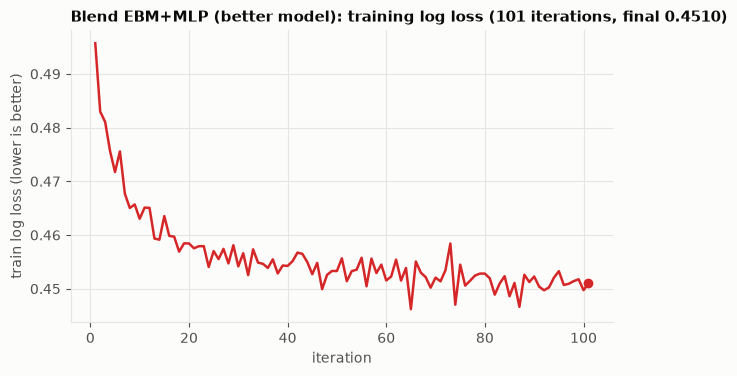

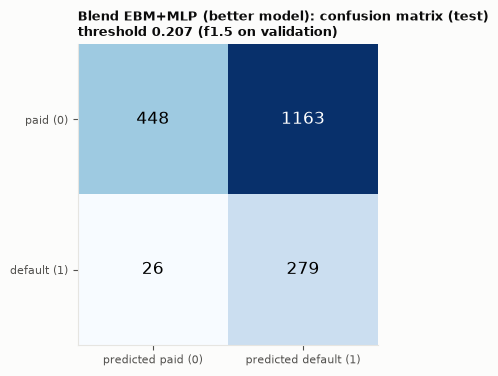

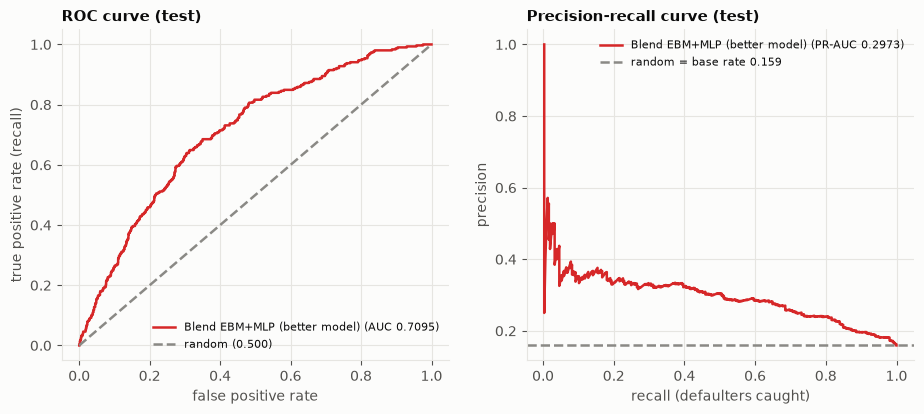


scratch vs library:
  Blend vs w * EBM + (1 - w) * mean(MLPs) recomputed by hand
    AUC scratch 0.7095 | AUC library 0.7096 | max |dP| (2nd AUC = MLP bag alone) = 0

saved + reloaded TrainedModels/Classification/15_Blend_EBM_MLP.joblib (identical predictions: True)


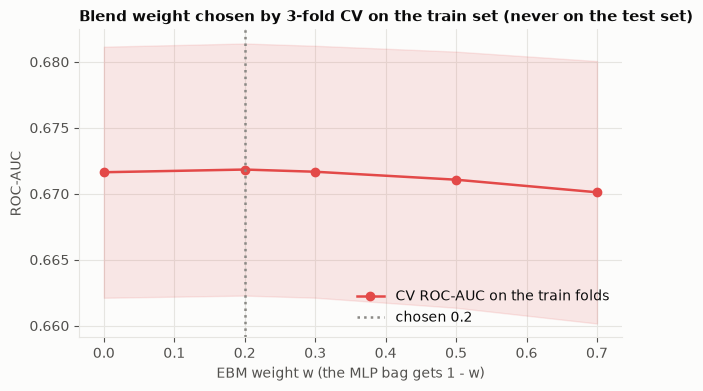


test borrower #2 (true label 1): P(EBM) = 0.237, P(MLP bag) = 0.212 -> P(blend) = 0.2 x 0.237 + 0.8 x 0.212 = 0.217
     EBM reason purpose_credit_card          -0.393
     EBM reason log.annual.inc               +0.183
     EBM reason purpose_debt_consolidation   +0.136
     EBM reason int.rate                     +0.126
     EBM reason policy_inquiry_risk          -0.113
     EBM reason installment                  -0.107


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Blend EBM+MLP (better model)", model, d, check)

# the weight search as a chart
search.to_csv(out.table("blend_weight_search.csv"))
fig, ax = plots.plt.subplots(figsize=(7, 4))
ax.plot(search.index, search["CV ROC-AUC"], "o-", color=plots.RED, label="CV ROC-AUC on the train folds")
ax.fill_between(
    search.index,
    search["CV ROC-AUC"] - search["CV ROC-AUC SD"],
    search["CV ROC-AUC"] + search["CV ROC-AUC SD"],
    color=plots.RED,
    alpha=0.12,
)
ax.axvline(EBM_WEIGHT, color=plots.NEUTRAL, linestyle=":", label=f"chosen {EBM_WEIGHT}")
ax.set_xlabel("EBM weight w (the MLP bag gets 1 - w)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Blend weight chosen by 3-fold CV on the train set (never on the test set)")
ax.legend()
plots._save(fig, out.image("blend_weight_search.png"))

# one borrower through the blend: the EBM reasons + how far the MLP bag moves the final probability
flagged = np.where((d.y_te == 1) & (model.predict(d.X_te) == 1))[0]
i = int(flagged[0]) if len(flagged) else 0
e = model.explain(d.X_te[i : i + 1])
print(
    f"\ntest borrower #{i} (true label {int(d.y_te[i])}): P(EBM) = {e['p_ebm']:.3f}, P(MLP bag) = {e['p_mlp_bag']:.3f} "
    f"-> P(blend) = {EBM_WEIGHT} x {e['p_ebm']:.3f} + {1 - EBM_WEIGHT:.1f} x {e['p_mlp_bag']:.3f} = {e['p_blend']:.3f}"
)
for f, v in e["contributions"]:
    print(f"     EBM reason {f:<28} {v:+.3f}")